# Week 5 — Wavelet Denoising (VisuShrink) Applied to Minute Bar Prices

**Course:** IEOR E4576 — Data-Driven Models in Finance
**Reference:** D. L. Donoho and I. M. Johnstone (1994), "Ideal spatial adaptation by wavelet shrinkage", *Biometrika* 81(3), 425–455
**Companion reading:** `wavelet_denoising_reading.pdf`

## Overview

This notebook removes noise from a stock's 1-minute close prices with **wavelet shrinkage**,
using the **VisuShrink** rule of Donoho and Johnstone: transform the series, shrink the
coefficients with **soft thresholding**, and transform back.

### Key Idea

A wavelet transform rewrites a series as a coarse trend plus **detail coefficients** at
successively finer time scales (about 2, 4, 8, ... minutes). A smooth signal, even one with a
few sudden jumps, needs only a handful of large coefficients; noise spreads thinly over all of
them. Setting the small coefficients to zero removes most of the noise and keeps the signal,
including jumps that a moving average would smear out.

## 1. Imports

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pywt
from pykalman import KalmanFilter

plt.rcParams.update({"figure.figsize": (14, 6), "axes.grid": True,
                     "grid.alpha": 0.3, "font.size": 11})

BARS_H5 = Path("data/minute_bars.h5")
SYMBOL  = "AAPL"
WAVELET = "db4"     # Daubechies wavelet with 4 vanishing moments

## 2. Load Minute Bars from HDF5

We source data from the HDF5 file produced by `minute_bars.py`.

In [2]:
with pd.HDFStore(str(BARS_H5), mode="r") as store:
    bars = store[f"minute_bars/{SYMBOL}"]

prices = bars["close"].dropna()
print(f"Loaded {len(prices)} minute bars for {SYMBOL}")
print(f"Session: {prices.index[0]:%Y-%m-%d %H:%M} → {prices.index[-1]:%H:%M}")
prices.describe().rename("close price").to_frame()

Loaded 390 minute bars for AAPL
Session: 2019-10-30 09:30 → 15:59


,close price
count,390.000000
mean,242.615603
std,0.641130
min,241.290000
25%,242.070000
50%,242.565000
75%,243.087500
max,244.900000


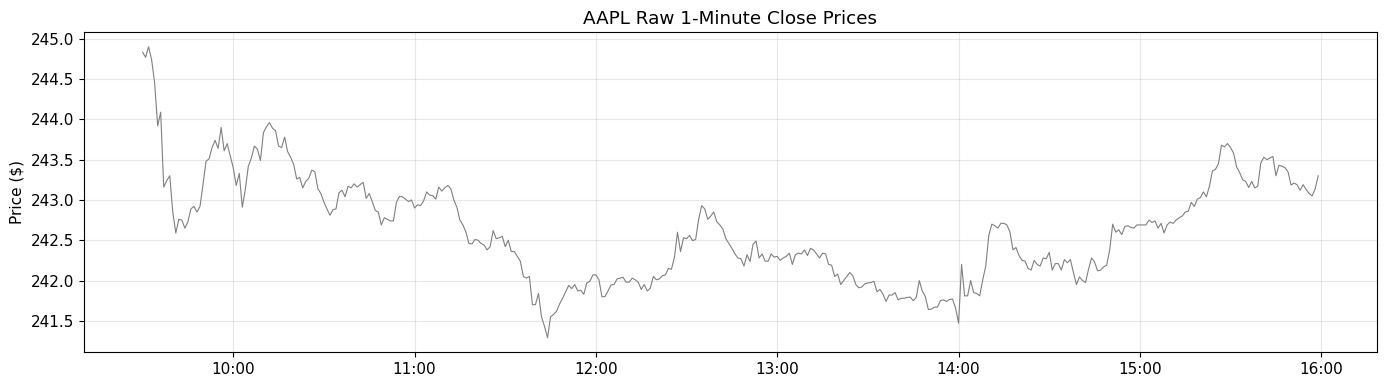

In [3]:
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(prices.index, prices.values, lw=0.8, color="gray")
ax.set_title(f"{SYMBOL} Raw 1-Minute Close Prices")
ax.set_ylabel("Price ($)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
plt.tight_layout()
plt.show()

## 3. What a Wavelet Transform Does

The simplest wavelet is the **Haar** wavelet. One level of the transform takes neighbouring
pairs $(x_1, x_2)$ and replaces them with a scaled **average** $(x_1+x_2)/\sqrt{2}$ and a scaled
**difference** $(x_1-x_2)/\sqrt{2}$. Repeating this on the averages gives a coarser level, and so on:

- **approximation** `cA`: the coarse trend that is left at the end,
- **details** `cD1, cD2, ...`: the differences at scale 2, 4, 8, ... observations.

The transform is exactly invertible and preserves the sum of squares, so nothing is lost.

A step function shows why wavelets suit signals with jumps: only one coefficient is non-zero.

In [4]:
x = np.array([10, 10, 10, 10, 14, 14, 14, 14], dtype=float)

coeffs = pywt.wavedec(x, "haar", level=3)          # [cA3, cD3, cD2, cD1]
for name, c in zip(["cA3", "cD3", "cD2", "cD1"], coeffs):
    print(f"{name}: {np.round(c, 3)}")

print("\nreconstructed:", pywt.waverec(coeffs, "haar"))

cA3: [33.941]
cD3: [-5.657]
cD2: [0. 0.]
cD1: [0. 0. 0. 0.]

reconstructed: [10. 10. 10. 10. 14. 14. 14. 14.]


### The same transform on AAPL minute closes

We use the smoother `db4` wavelet from here on. `wavedec` returns one array of coefficients per
level. Level 1 (`cD1`) holds the finest, 2-minute detail; the highest level holds the slowest
movements. Most finest-level coefficients are small: that is mostly noise.

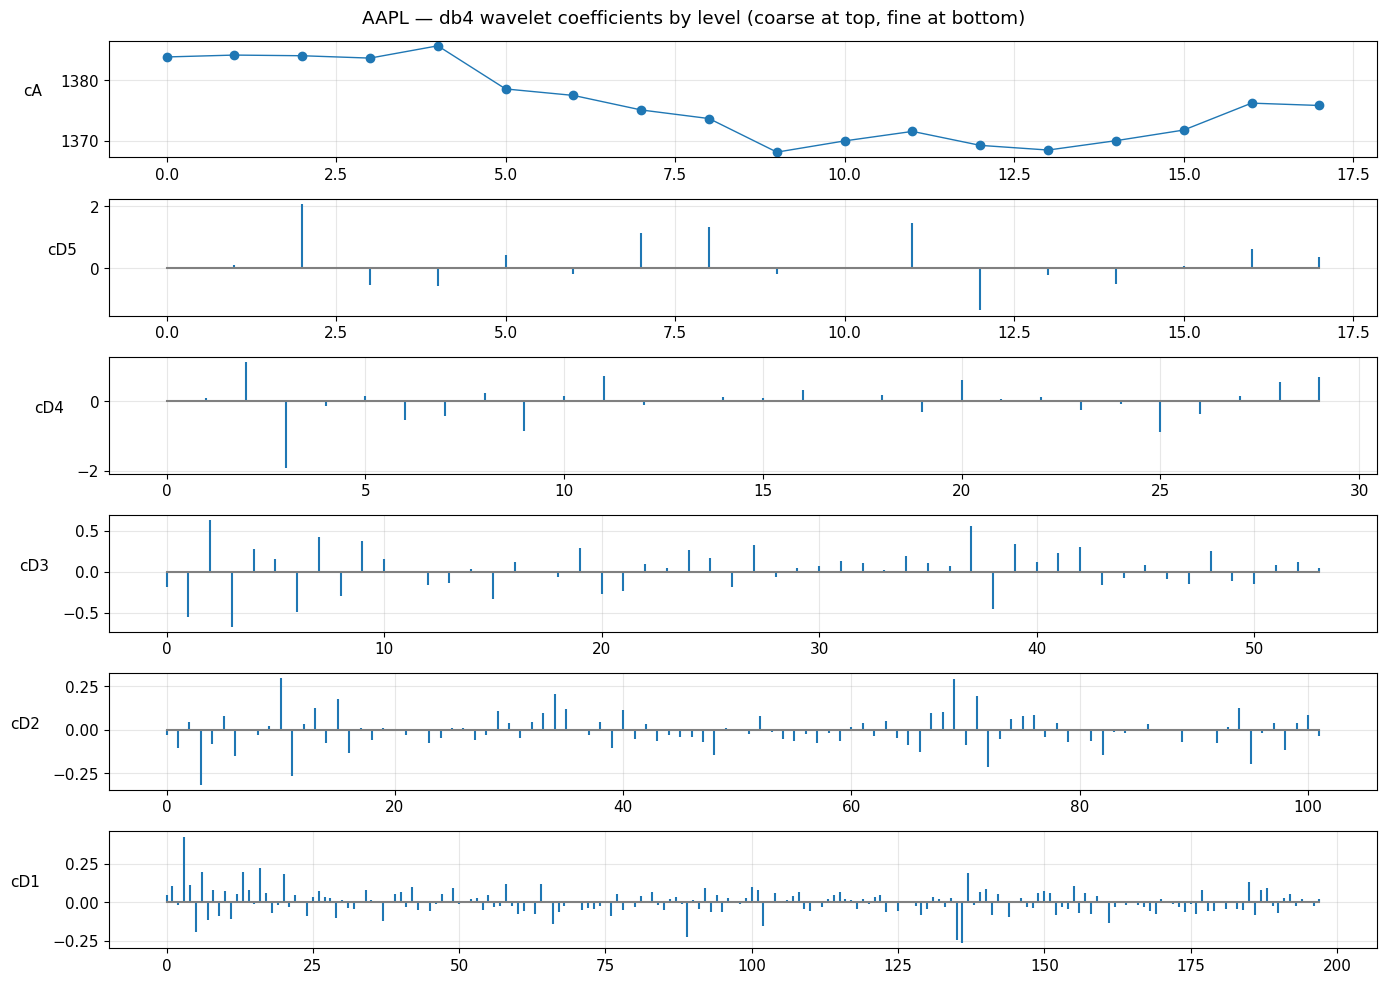

,coefficients,std
cA,18,5.937
cD5,18,0.818
cD4,30,0.561
cD3,54,0.259
cD2,102,0.096
cD1,198,0.078


In [5]:
coeffs = pywt.wavedec(prices.values, WAVELET)
names = ["cA"] + [f"cD{j}" for j in range(len(coeffs) - 1, 0, -1)]

fig, axes = plt.subplots(len(coeffs), 1, figsize=(14, 10))
for ax, name, c in zip(axes, names, coeffs):
    if name == "cA":
        ax.plot(c, marker="o", lw=1)                 # coarse trend: plot levels, not stems
    else:
        ax.stem(c, markerfmt=" ", basefmt="gray")
    ax.set_ylabel(name, rotation=0, labelpad=20)
fig.suptitle(f"{SYMBOL} — {WAVELET} wavelet coefficients by level (coarse at top, fine at bottom)")
plt.tight_layout()
plt.show()

pd.DataFrame({"coefficients": [len(c) for c in coeffs],
              "std": [np.std(c) for c in coeffs]}, index=names).round(3)

## 4. VisuShrink: Soft Thresholding with the Universal Threshold

Model: observed price = signal + noise, $y_t = f_t + \sigma\varepsilon_t$ with $\varepsilon_t$ i.i.d. $N(0,1)$.
VisuShrink works in four steps:

1. **Transform**: compute the wavelet coefficients of $y$.
2. **Estimate the noise level** from the finest details, which are almost pure noise:
   $\hat\sigma = \mathrm{median}(|d_1|)/0.6745$. (0.6745 is the median absolute value of a standard normal,
   so the median is a robust stand-in for the standard deviation.)
3. **Soft-threshold** every detail coefficient at the **universal threshold**
   $\lambda = \hat\sigma\sqrt{2\ln n}$:
   $\eta_\lambda(d) = \mathrm{sign}(d)\max(|d| - \lambda, 0)$.
   With $n$ pure-noise coefficients, the largest is about $\sigma\sqrt{2\ln n}$, so this threshold
   removes essentially all of the noise.
4. **Invert** the transform.

**Hard** thresholding keeps coefficients above $\lambda$ unchanged; **soft** thresholding also
shrinks them towards zero by $\lambda$. Soft gives smoother reconstructions, at the cost of
biasing the large, genuine coefficients towards zero.

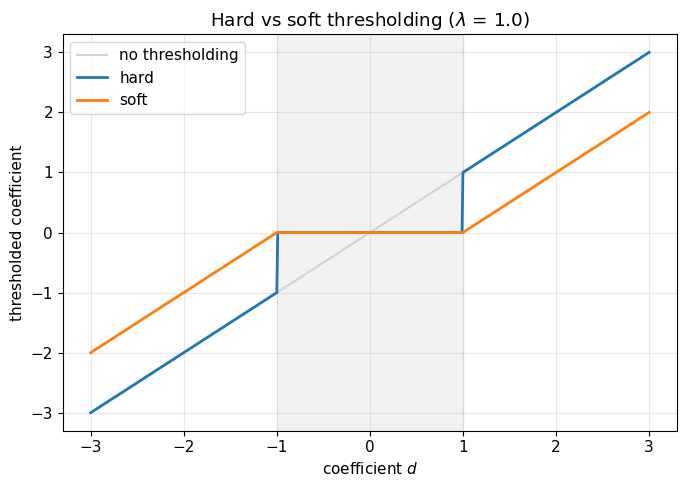

In [6]:
d = np.linspace(-3, 3, 601)
lam = 1.0

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(d, d, color="lightgray", label="no thresholding")
ax.plot(d, pywt.threshold(d, lam, mode="hard"), lw=2, label="hard")
ax.plot(d, pywt.threshold(d, lam, mode="soft"), lw=2, label="soft")
ax.axvspan(-lam, lam, color="gray", alpha=0.1)
ax.set_xlabel("coefficient $d$")
ax.set_ylabel("thresholded coefficient")
ax.set_title(f"Hard vs soft thresholding ($\\lambda$ = {lam})")
ax.legend()
plt.tight_layout()
plt.show()

In [7]:
def visushrink(x, wavelet=WAVELET, mode="soft"):
    # Donoho-Johnstone VisuShrink: threshold all detail coefficients at sigma * sqrt(2 ln n).
    x = np.asarray(x, dtype=float)
    coeffs = pywt.wavedec(x, wavelet)
    sigma = np.median(np.abs(coeffs[-1])) / 0.6745          # noise level from finest details
    lam = sigma * np.sqrt(2 * np.log(len(x)))                # universal threshold
    shrunk = [coeffs[0]] + [pywt.threshold(c, lam, mode=mode) for c in coeffs[1:]]
    kept = sum(int(np.count_nonzero(c)) for c in shrunk[1:])
    total = sum(len(c) for c in coeffs[1:])
    return pywt.waverec(shrunk, wavelet)[:len(x)], {"sigma": sigma, "lambda": lam,
                                                     "kept": kept, "total": total}

## 5. Sanity Check on a Signal with Known Truth

Before using real prices, where the "true" signal is unknown, we test VisuShrink on a
piecewise-constant signal plus Gaussian noise, similar to Donoho and Johnstone's *Blocks*
example. We compare soft VisuShrink (the original rule), the same threshold applied hard, and a
centred moving average, and measure the error near the jumps and on the flat stretches.

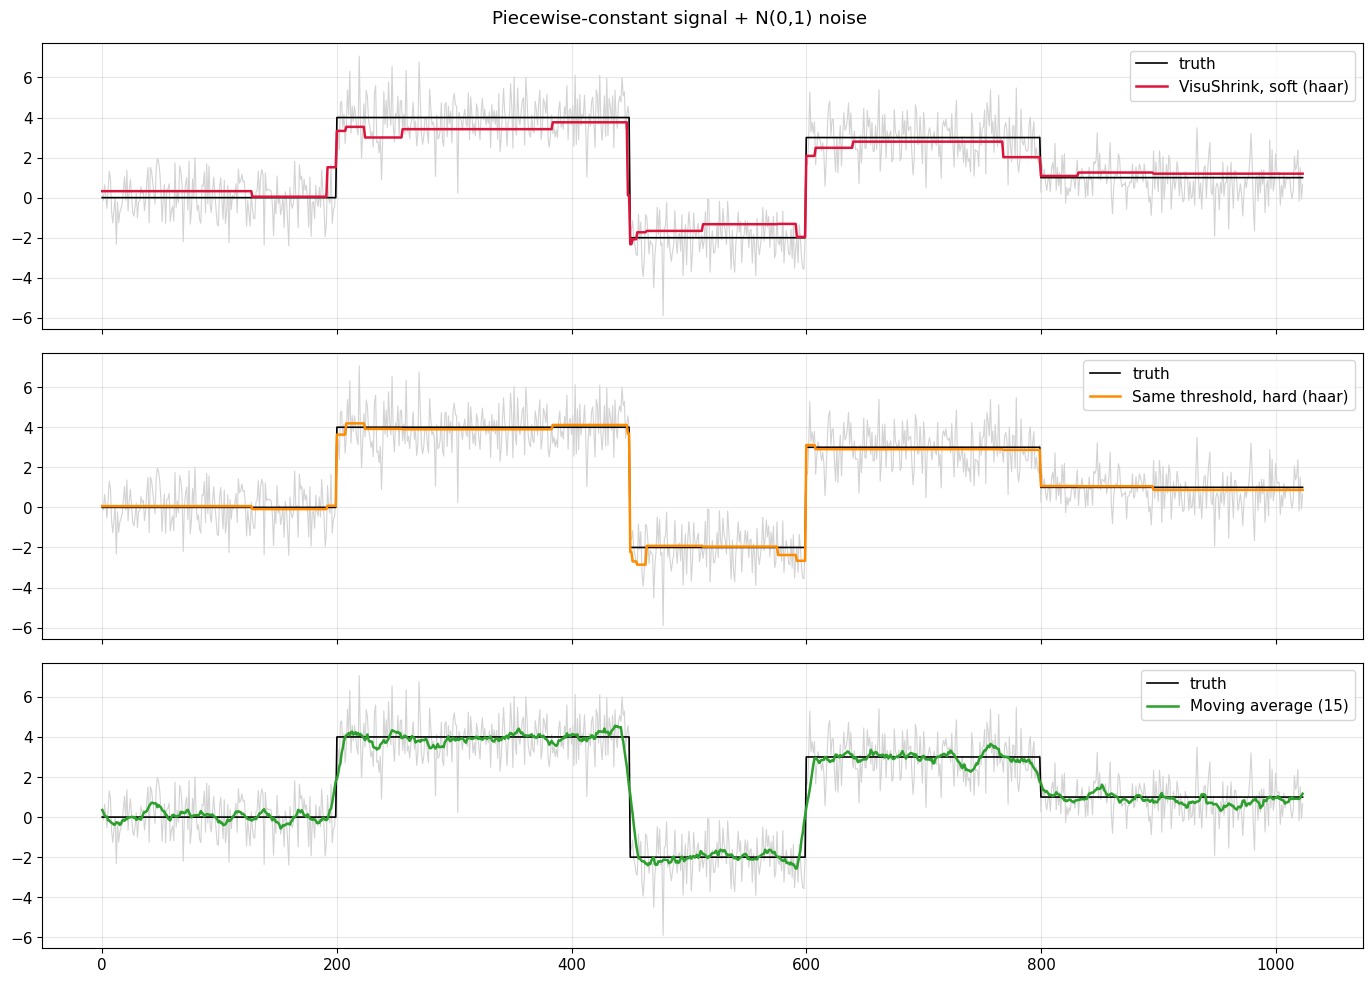

estimated sigma = 0.932 (true 1.000),  lambda = 3.471
kept 20 of 1023 detail coefficients


,noisy,VisuShrink soft,VisuShrink hard,moving average (15)
RMSE overall,0.973,0.496,0.153,0.387
RMSE near jumps,0.915,0.945,0.365,1.099
RMSE flat stretches,0.978,0.437,0.119,0.244


In [8]:
rng = np.random.default_rng(0)
n = 1024
t = np.arange(n)
truth = np.select([t < 200, t < 450, t < 600, t < 800], [0.0, 4.0, -2.0, 3.0], 1.0)
noisy = truth + rng.normal(0, 1, n)

soft, info = visushrink(noisy, wavelet="haar", mode="soft")
hard, _ = visushrink(noisy, wavelet="haar", mode="hard")
ma = pd.Series(noisy).rolling(15, center=True, min_periods=1).mean().values

fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True, sharey=True)
for ax, (label, est, color) in zip(axes, [("VisuShrink, soft (haar)", soft, "crimson"),
                                          ("Same threshold, hard (haar)", hard, "darkorange"),
                                          ("Moving average (15)", ma, "tab:green")]):
    ax.plot(t, noisy, color="lightgray", lw=0.8)
    ax.plot(t, truth, color="black", lw=1.2, label="truth")
    ax.plot(t, est, color=color, lw=1.8, label=label)
    ax.legend(loc="upper right")
fig.suptitle("Piecewise-constant signal + N(0,1) noise")
plt.tight_layout()
plt.show()

near = np.zeros(n, dtype=bool)                     # within 10 points of a jump
for jump in [200, 450, 600, 800]:
    near[jump - 10:jump + 10] = True
rmse = lambda est, mask: np.sqrt(np.mean((est - truth)[mask] ** 2))

print(f"estimated sigma = {info['sigma']:.3f} (true 1.000),  lambda = {info['lambda']:.3f}")
print(f"kept {info['kept']} of {info['total']} detail coefficients")
pd.DataFrame({name: {"RMSE overall": rmse(est, np.ones(n, dtype=bool)),
                     "RMSE near jumps": rmse(est, near),
                     "RMSE flat stretches": rmse(est, ~near)}
              for name, est in {"noisy": noisy, "VisuShrink soft": soft,
                                "VisuShrink hard": hard, "moving average (15)": ma}.items()}).round(3)

Three things to notice. First, the noise level is estimated from the data alone, with no tuning.
Second, near the jumps both wavelet estimates beat the moving average, which rounds every jump
off over its window. Third, on the flat stretches soft VisuShrink does worse than the moving
average: shrinking every surviving coefficient by $\lambda$ pulls the levels towards each other.
The same threshold applied *hard* avoids this bias and has the lowest error overall. Soft
VisuShrink trades accuracy for smoothness.

## 6. VisuShrink on AAPL Minute Closes

We apply VisuShrink to the whole day and compare it with the Kalman filter from
`kalman_filter.ipynb` (random walk + noise, $Q = 0.01$, $R = 1$).

sigma = 0.0651  lambda = 0.2249  kept 53 of 402 detail coefficients


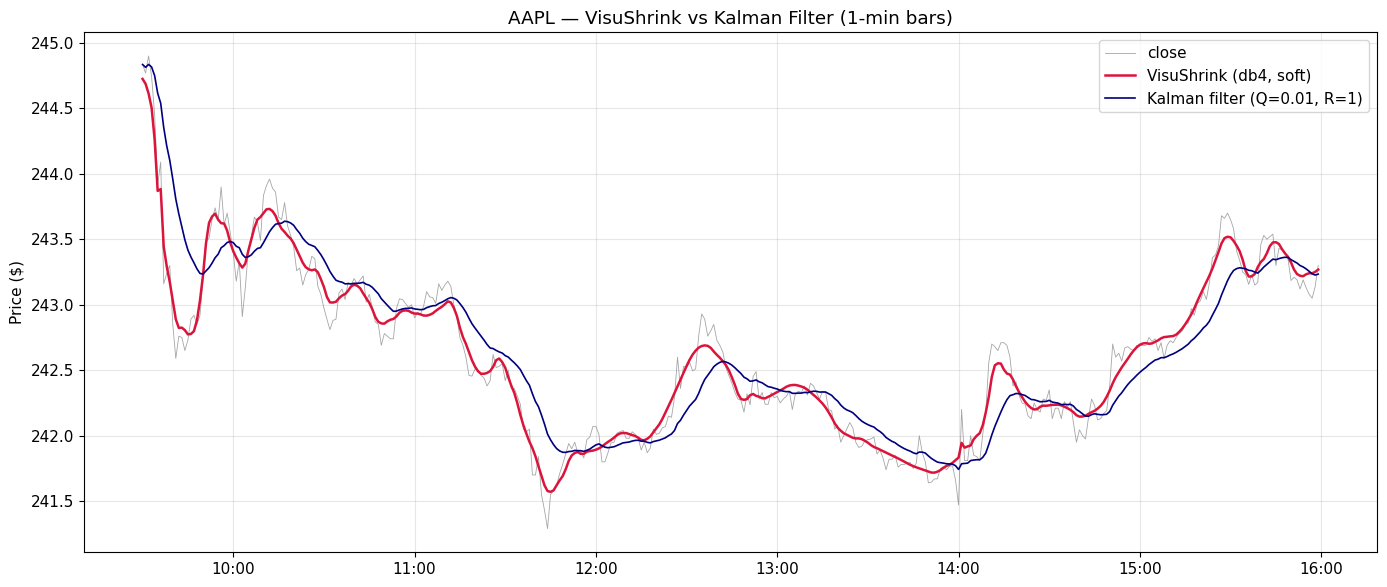

In [9]:
den, info = visushrink(prices.values)
print(f"sigma = {info['sigma']:.4f}  lambda = {info['lambda']:.4f}  "
      f"kept {info['kept']} of {info['total']} detail coefficients")

kf = KalmanFilter(transition_matrices=[1], observation_matrices=[1],
                  initial_state_mean=prices.iloc[0], initial_state_covariance=1,
                  observation_covariance=1.0, transition_covariance=0.01)
state_means, _ = kf.filter(prices.values)

result = prices.to_frame("close")
result["visushrink"] = den
result["kalman"] = state_means.flatten()

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(result.index, result["close"], lw=0.6, color="gray", alpha=0.7, label="close")
ax.plot(result.index, result["visushrink"], lw=1.8, color="crimson", label=f"VisuShrink ({WAVELET}, soft)")
ax.plot(result.index, result["kalman"], lw=1.2, color="navy", label="Kalman filter (Q=0.01, R=1)")
ax.set_title(f"{SYMBOL} — VisuShrink vs Kalman Filter (1-min bars)")
ax.set_ylabel("Price ($)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax.legend()
plt.tight_layout()
plt.show()

## 7. Choice of Wavelet and Thresholding Rule

The universal threshold is fixed by the data, so the main choices are the wavelet and the
thresholding rule. Haar gives piecewise-constant output; smoother wavelets (`db4`, `sym8`)
give smoother curves. Hard thresholding keeps more detail but is noisier.

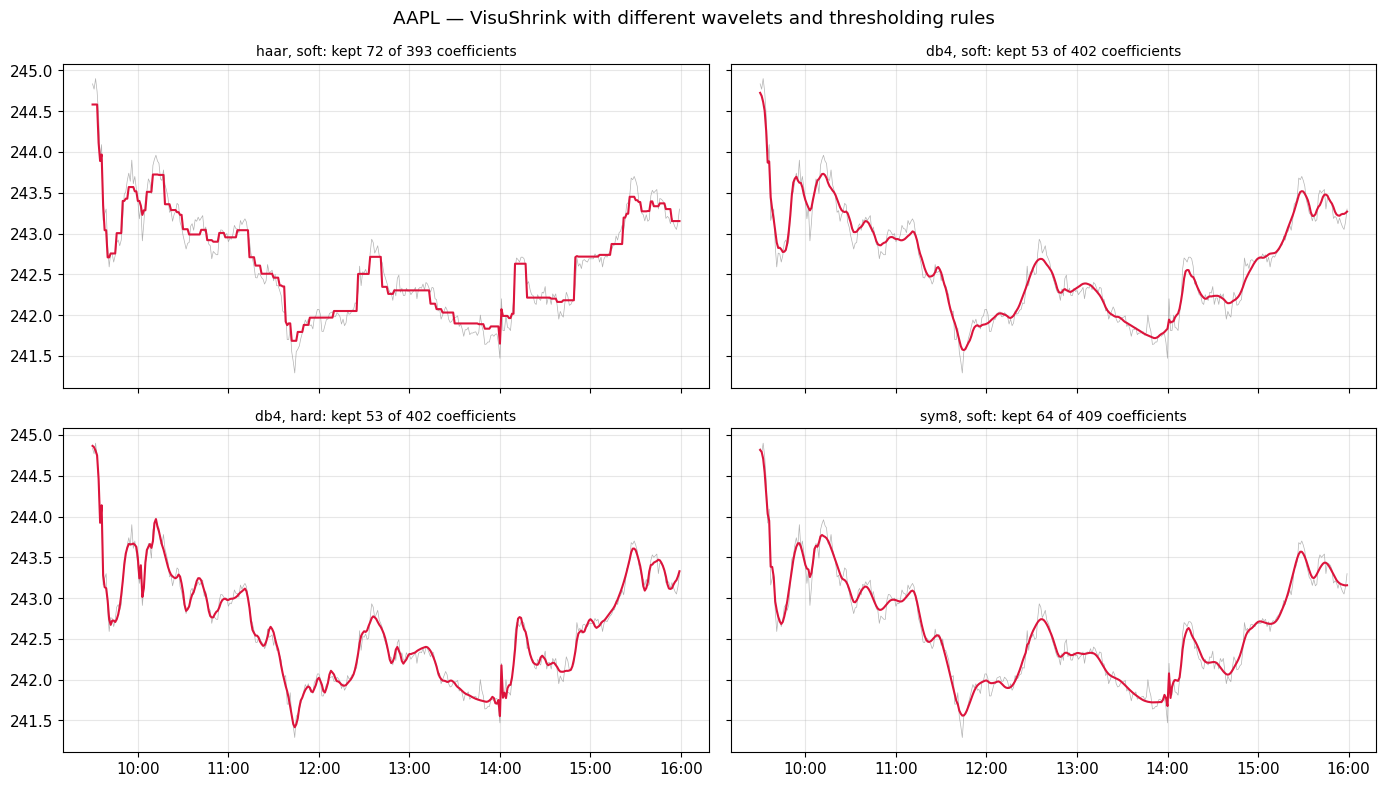

In [10]:
configs = [("haar", "soft"), ("db4", "soft"), ("db4", "hard"), ("sym8", "soft")]

fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True, sharey=True)
for ax, (wavelet, mode) in zip(axes.flat, configs):
    est, inf = visushrink(prices.values, wavelet=wavelet, mode=mode)
    ax.plot(prices.index, prices.values, lw=0.5, color="gray", alpha=0.6)
    ax.plot(prices.index, est, lw=1.5, color="crimson")
    ax.set_title(f"{wavelet}, {mode}: kept {inf['kept']} of {inf['total']} coefficients", fontsize=10)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
fig.suptitle(f"{SYMBOL} — VisuShrink with different wavelets and thresholding rules")
plt.tight_layout()
plt.show()

## 8. Look-Ahead: VisuShrink Is Not Causal

The transform uses the **whole day**, so the denoised price at 10:00 depends on prices after
10:00. That is fine for describing the day afterwards, but it cannot be traded.

A **causal** version only uses the past: at each minute, denoise the last `WINDOW` minutes and
keep the last point. The last point sits at the edge of the window, where wavelet estimates are
least accurate, and the shorter window gives a smaller threshold, so the causal version follows
the price more closely but is much rougher.

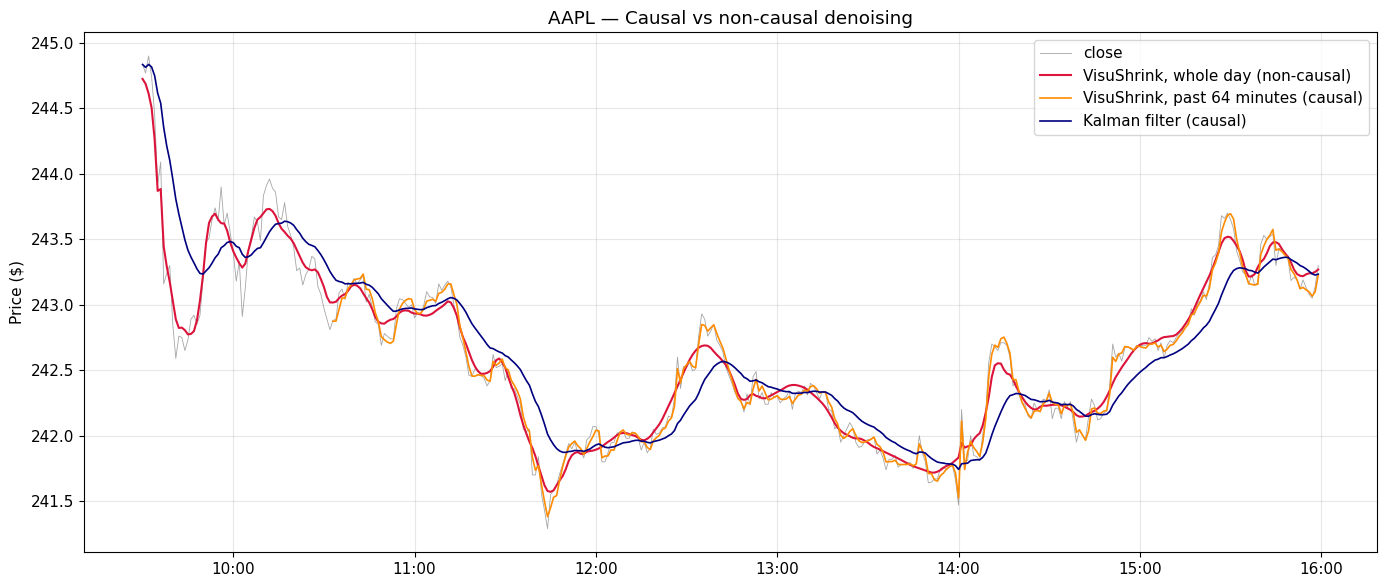

In [11]:
WINDOW = 64

def causal_visushrink(x, window=WINDOW, wavelet=WAVELET):
    # At each t, denoise x[t-window+1 .. t] and keep the last value: uses past data only.
    x = np.asarray(x, dtype=float)
    out = np.full(len(x), np.nan)
    for t in range(window - 1, len(x)):
        out[t] = visushrink(x[t - window + 1:t + 1], wavelet=wavelet)[0][-1]
    return out

result["visushrink_causal"] = causal_visushrink(prices.values)

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(result.index, result["close"], lw=0.6, color="gray", alpha=0.7, label="close")
ax.plot(result.index, result["visushrink"], lw=1.5, color="crimson", label="VisuShrink, whole day (non-causal)")
ax.plot(result.index, result["visushrink_causal"], lw=1.2, color="darkorange",
        label=f"VisuShrink, past {WINDOW} minutes (causal)")
ax.plot(result.index, result["kalman"], lw=1.2, color="navy", label="Kalman filter (causal)")
ax.set_title(f"{SYMBOL} — Causal vs non-causal denoising")
ax.set_ylabel("Price ($)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax.legend()
plt.tight_layout()
plt.show()

## 9. Statistics

In [12]:
cols = {"VisuShrink (whole day)": "visushrink", f"VisuShrink (causal, {WINDOW}m)": "visushrink_causal",
        "Kalman filter": "kalman"}
sample = result.dropna()          # same minutes for every method

stats = pd.DataFrame({
    name: {"mean_abs_dev":  (sample["close"] - sample[col]).abs().mean(),
           "std_dev":       (sample["close"] - sample[col]).std(),
           "corr_close":     sample["close"].corr(sample[col]),
           "roughness":      sample[col].diff().abs().mean()}
    for name, col in cols.items()})
stats.round(4)

,VisuShrink (whole day),"VisuShrink (causal, 64m)",Kalman filter
mean_abs_dev,0.0765,0.0369,0.1632
std_dev,0.0985,0.0467,0.2185
corr_close,0.9823,0.9960,0.9085
roughness,0.0262,0.0530,0.0171


`mean_abs_dev` and `std_dev` measure how far each estimate sits from the observed close;
`roughness` is the average absolute minute-to-minute change of the estimate (lower is smoother).

## Summary

| Concept | Description |
|---------|-------------|
| **Wavelet transform** | Rewrites the series as a coarse trend plus details at scales 2, 4, 8, ... minutes; exactly invertible |
| **Sparsity** | A signal needs few large coefficients; noise spreads over all of them |
| **Noise estimate** | $\hat\sigma = \mathrm{median}(\lvert d_1\rvert)/0.6745$ from the finest details |
| **Universal threshold** | $\lambda = \hat\sigma\sqrt{2\ln n}$: removes almost all pure-noise coefficients |
| **Soft thresholding** | $\eta_\lambda(d) = \mathrm{sign}(d)\max(\lvert d\rvert-\lambda,0)$ |
| **VisuShrink** | Transform, soft-threshold the details at $\lambda$, invert |
| **Causality** | The whole-day transform looks ahead; a rolling window of past data is causal but less accurate at the edge |

### Key Takeaways

1. VisuShrink needs **no tuning**: the threshold comes from the data's own noise level.
2. Unlike a moving average, it keeps **jumps sharp**.
3. Soft thresholding **biases** large coefficients towards zero: the result is smooth, but hard
   thresholding at the same $\lambda$ is often more accurate.
4. The universal threshold is conservative, so small real moves may be removed along with the noise.
5. Applied to a whole day it **looks ahead**; only the rolling, past-only version can be used for trading.